
# Skin Lesion Triage: Fine-tuned ResNet18, Offline Raspberry Pi Pipeline

Demo framework notebook, simplified to a single backbone: **ResNet18**, chosen specifically
because of the three options considered (ResNet18 / MONET / Google Derm Foundation), it's the only
one light enough (11M params) for real-time INT8 inference on a Raspberry Pi. MONET (~300M+ param
CLIP model) and Derm Foundation (TensorFlow-only, 6144-d embeddings) are richer dermatology-specific
features but not realistic on-device targets -- keep them as a future server-side comparison, not
this pipeline's job.

What this notebook does:
1. Loads a labelled skin-lesion dataset (PAD-UFES-20, BCN20000, HAM10000; this branch uses
   HAM10000 only) and splits it **by lesion**, so no lesion appears in both train and test.
2. Computes **dataset-specific mean/std** instead of using generic ImageNet normalization.
3. **Fine-tunes** ResNet18's last block (`layer4`) together with a small head, using a smaller
   learning rate for the pretrained layers. **Early stopping** keeps the epoch with the best
   validation sensitivity at a 60% quality drop. The weights are then frozen for export --
   nothing learns on the Pi.
4. Trains that head with a **contrastive alignment loss** between clean and simulated-degraded
   versions of the same lesion image, addressing the "low-quality phone photo vs. clinical image"
   domain gap directly, not just via augmentation.
5. Reports **sensitivity retained vs. a clean baseline as a function of simulated image-quality
   drop** (0-80%) -- so "preserves sensitivity under a 60% quality drop" is a number read off a
   measured curve, not an assumption.
6. Produces an **INT8-quantized, ONNX-exported artifact** sized for the Pi, and re-measures the
   same sensitivity-vs-quality curve on that quantized artifact specifically.
7. Adds a **Grad-CAM** overlay for the "why did it flag this" explanation the clinical-kit UI needs.

**Scope note:** this notebook produces the trained/quantized/exported model. The Raspberry Pi
camera-feed kit itself (the physical clinical device) is a separate, smaller follow-on project that
loads this notebook's ONNX output into an inference loop -- see the roadmap cell near the end.

**This is a scaffold, not a validated clinical tool.** Swap in real data and take the fairness
(Fitzpatrick-stratified) results seriously before treating any output as more than a research
prototype.

Requirements (not auto-installed by this notebook):
```
pip install torch torchvision scikit-learn pillow pandas numpy matplotlib onnx onnxruntime onnxscript
```


In [1]:

import os, io, time, random, warnings
import copy
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image, ImageFilter

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms

from sklearn.metrics import roc_auc_score, recall_score, accuracy_score

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")


Using device: cuda



## 1. Config

`n_synthetic` only sizes the placeholder dataset used when no CSV is found. `eval_quality_levels` sets the exact percentages
the sensitivity-retention curve is measured at (0/20/40/60/80 by default, so a 60%-drop claim is
one of the measured points).


In [2]:

@dataclass
class Config:
    # --- data ---
    data_csv: str = "data/labels_ham.csv"       # HAM10000-only run. columns: image_path,diagnosis[,fitzpatrick,source,lesion_id]
    img_dir: str = ""                            # empty: image_path in the CSV is used as-is (relative to notebooks/)
    img_size: int = 224
    load_max_size: int = 224                     # shrink on load to the model input size, so degradation runs at 224px too
    cache_images: bool = True                    # keep loaded images in RAM (~1.5 GB for PAD) so disk is read once
    val_frac: float = 0.10                       # 80/10/10 train/val/test split (by lesion)
    test_frac: float = 0.10
    use_synthetic_if_missing: bool = True
    n_synthetic: int = 800                       # size of the synthetic placeholder set (only used without a CSV)

    # --- head ---
    proj_dim: int = 128
    head_hidden: int = 128
    head_dropout: float = 0.2

    # --- training ---
    batch_size: int = 16
    epochs: int = 30                             # upper limit; early stopping usually ends sooner
    patience: int = 6                            # stop after this many epochs without a new best val score
    early_stop_quality_drop: float = 60.0        # model selection: val mean sensitivity at this quality drop
    lr: float = 1e-3                             # head learning rate
    backbone_lr: float = 1e-4                    # layer4's learning rate: 10x smaller than the head, adjusts pretrained features gently
    layer_lr_decay: float = 0.5                  # each earlier block trains at this fraction of the next one's LR
    finetune_layers: tuple = ("layer4",)         # backbone layers to train; ("all",) = everything, () = fully frozen
    lr_schedule: str = "cosine"                  # "cosine" (lower LRs gradually over `epochs`) or "none"
    augment: bool = True                         # random flips + 90-degree rotations on training images
    normalization: str = "imagenet"              # "imagenet" (matches the pretrained backbone) or "dataset" (own mean/std)
    tta: bool = True                             # test-time augmentation: average each prediction with its mirror image
    weight_decay: float = 1e-4
    class_weights: tuple = None                  # None: inverse class frequency from the train split
    contrastive_weight: float = 0.5              # lambda on the clean/degraded alignment loss
    contrastive_temperature: float = 0.1
    train_degrade_min_pct: float = 10.0
    train_degrade_max_pct: float = 70.0          # trains across a *range* of degradation severities

    # --- degradation model (all tied to one 0-100 "quality drop" knob) ---
    jpeg_quality_floor: int = 15                 # jpeg quality at 100% simulated quality drop
    blur_radius_max: float = 4.0
    noise_std_max: float = 0.12
    downsample_factor_max: float = 6.0

    # --- evaluation ---
    eval_quality_levels: tuple = (0, 20, 40, 60, 80)

    # --- quantization / export (Raspberry Pi deployment artifact) ---
    onnx_path: str = "outputs/melanoma_resnet18_fp32.onnx"
    onnx_int8_path: str = "outputs/melanoma_resnet18_int8.onnx"
    torch_int8_path: str = "outputs/melanoma_resnet18_dynamic_int8.pt"
    class_names_path: str = "outputs/class_names.json"  # logit index -> lesion type, for the Pi


CFG = Config()
os.makedirs("outputs", exist_ok=True)
CFG


Config(data_csv='data/labels_ham.csv', img_dir='', img_size=224, load_max_size=224, cache_images=True, val_frac=0.1, test_frac=0.1, use_synthetic_if_missing=True, n_synthetic=800, proj_dim=128, head_hidden=128, head_dropout=0.2, batch_size=16, epochs=30, patience=6, early_stop_quality_drop=60.0, lr=0.001, backbone_lr=0.0001, layer_lr_decay=0.5, finetune_layers=('layer3', 'layer4'), lr_schedule='cosine', augment=True, normalization='imagenet', tta=True, weight_decay=0.0001, class_weights=None, contrastive_weight=0.5, contrastive_temperature=0.1, train_degrade_min_pct=10.0, train_degrade_max_pct=70.0, jpeg_quality_floor=15, blur_radius_max=4.0, noise_std_max=0.12, downsample_factor_max=6.0, eval_quality_levels=(0, 20, 40, 60, 80), onnx_path='outputs/melanoma_resnet18_fp32.onnx', onnx_int8_path='outputs/melanoma_resnet18_int8.onnx', torch_int8_path='outputs/melanoma_resnet18_dynamic_int8.pt', class_names_path='outputs/class_names.json')


## 2. Data

Expects a CSV with `image_path,diagnosis[,fitzpatrick]`. `diagnosis` is the lesion type as text
(PAD-UFES-20: `ACK, BCC, MEL, NEV, SCC, SEK`). The class list is built from whichever types
appear, so adding a dataset with new types just adds classes.
`fitzpatrick` (skin type I-VI) is optional but strongly recommended -- without it you can't check
whether the model is quietly failing on darker skin tones, the single most common failure mode in
published dermatology AI.

If no CSV is found, a synthetic placeholder dataset of `CFG.n_synthetic` images is generated so the
rest of the notebook still runs end to end. It is **not** real data and proves nothing about model
performance -- it only exercises the code paths.


In [3]:

_IMAGE_CACHE = {}


def load_pil(row, img_dir, max_size=None):
    if "image" in row and isinstance(row["image"], Image.Image):
        return row["image"]
    path = Path(img_dir) / row["image_path"] if img_dir else Path(row["image_path"])
    max_size = max_size or CFG.load_max_size
    key = (str(path), max_size)
    if key in _IMAGE_CACHE:
        return _IMAGE_CACHE[key]  # callers never modify it in place (degrade_image returns new images)
    img = Image.open(path).convert("RGB")
    if max(img.size) > max_size:
        img.thumbnail((max_size, max_size), Image.BILINEAR)  # keeps aspect ratio
    if CFG.cache_images:
        _IMAGE_CACHE[key] = img
    return img


def make_synthetic_dataset(n, seed=SEED):
    """
    DEMO ONLY. Generates random-noise placeholder images with a synthetic melanoma label so the
    pipeline can be exercised without a real dataset. Replace with real ISIC/HAM10000-derived data
    before drawing any conclusions from this notebook.
    """
    rng = np.random.RandomState(seed)
    rows = []
    for _ in range(n):
        is_mel = int(rng.rand() < 0.18)  # roughly mimics melanoma prevalence in ISIC-style sets
        base_color = rng.randint(120, 200, size=3) if not is_mel else rng.randint(60, 140, size=3)
        arr = np.ones((256, 256, 3), dtype=np.uint8) * base_color.astype(np.uint8)
        noise = rng.randint(-25, 25, size=(256, 256, 3))
        arr = np.clip(arr.astype(int) + noise, 0, 255).astype(np.uint8)
        img = Image.fromarray(arr)
        fitz = int(rng.randint(1, 7))
        rows.append({"image": img, "diagnosis": "MEL" if is_mel else "NEV", "fitzpatrick": fitz})
    return pd.DataFrame(rows)


def load_records(cfg):
    csv_path = Path(cfg.data_csv)
    if csv_path.exists():
        df = pd.read_csv(csv_path)
        assert {"image_path", "diagnosis"}.issubset(df.columns), "CSV needs image_path,diagnosis columns"
        return df
    if cfg.use_synthetic_if_missing:
        print(f"'{csv_path}' not found -- generating {cfg.n_synthetic} synthetic demo records "
              f"(deliberately small, matching the low-data scenario).")
        return make_synthetic_dataset(cfg.n_synthetic)
    raise FileNotFoundError(f"No data at {csv_path} and use_synthetic_if_missing=False")


def split_records(df, val_frac, test_frac, seed=SEED):
    """Splits by lesion: every photo of one lesion lands in the same split, so the test set never
    contains a lesion the model trained on. Falls back to one group per image without lesion_id."""
    groups = df["lesion_id"] if "lesion_id" in df.columns else pd.Series(range(len(df)), index=df.index)
    lesions = groups.drop_duplicates().sample(frac=1.0, random_state=seed)
    n = len(lesions)
    n_test, n_val = int(n * test_frac), int(n * val_frac)
    test_ids, val_ids = set(lesions.iloc[:n_test]), set(lesions.iloc[n_test:n_test + n_val])
    split = groups.map(lambda g: "test" if g in test_ids else "val" if g in val_ids else "train")
    df = df.sample(frac=1.0, random_state=seed)  # shuffled image order within each split
    return tuple(df[split.loc[df.index] == s].reset_index(drop=True) for s in ("train", "val", "test"))


records = load_records(CFG)
CLASS_NAMES = sorted(records["diagnosis"].unique())  # label i <-> CLASS_NAMES[i]
records["label"] = records["diagnosis"].map({c: i for i, c in enumerate(CLASS_NAMES)})
train_df, val_df, test_df = split_records(records, CFG.val_frac, CFG.test_frac)
print(f"train={len(train_df)} val={len(val_df)} test={len(test_df)}  classes={CLASS_NAMES}")
print("test images per class:", test_df["diagnosis"].value_counts().reindex(CLASS_NAMES, fill_value=0).to_dict())


train=7974 val=1010 test=1031  classes=['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc']
test images per class: {'akiec': 32, 'bcc': 68, 'bkl': 121, 'df': 16, 'mel': 118, 'nv': 657, 'vasc': 19}



## 3. Degradation model: one knob, four effects

"Image quality dropped by X%" isn't a single physical quantity, so this notebook defines it
concretely: `degrade_image(img, quality_drop_pct)` scales JPEG compression, Gaussian blur, sensor
noise, and downsample/upsample blur together, linearly, from `quality_drop_pct=0` (untouched) to
`quality_drop_pct=100` (worst case, all four maxed out). Used both as a training-time augmentation
(sampled from a range) and as the fixed axis for the sensitivity-retention evaluation later.


In [4]:

def _severity(pct, max_val, min_val=0.0):
    pct = max(0.0, min(100.0, pct))
    return min_val + (max_val - min_val) * (pct / 100.0)


def jpeg_compress(img, pct, cfg):
    quality = int(100 - _severity(pct, 100 - cfg.jpeg_quality_floor))
    quality = max(cfg.jpeg_quality_floor, quality)
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=quality)
    buf.seek(0)
    return Image.open(buf).convert("RGB")


def gaussian_blur(img, pct, cfg):
    radius = _severity(pct, cfg.blur_radius_max)
    if radius <= 0:
        return img
    return img.filter(ImageFilter.GaussianBlur(radius=radius))


def add_sensor_noise(img, pct, cfg):
    std = _severity(pct, cfg.noise_std_max)
    if std <= 0:
        return img
    arr = np.asarray(img).astype(np.float32) / 255.0
    noisy = np.clip(arr + np.random.normal(0, std, arr.shape), 0, 1) * 255.0
    return Image.fromarray(noisy.astype(np.uint8))


def downsample_upsample(img, pct, cfg):
    factor = 1.0 + _severity(pct, cfg.downsample_factor_max - 1.0)
    if factor <= 1.0:
        return img
    w, h = img.size
    small = img.resize((max(1, int(w / factor)), max(1, int(h / factor))), Image.BILINEAR)
    return small.resize((w, h), Image.BILINEAR)


def degrade_image(img, quality_drop_pct, cfg=None):
    cfg = cfg or CFG
    img = jpeg_compress(img, quality_drop_pct, cfg)
    img = gaussian_blur(img, quality_drop_pct, cfg)
    img = add_sensor_noise(img, quality_drop_pct, cfg)
    img = downsample_upsample(img, quality_drop_pct, cfg)
    return img



## 4. ResNet18 backbone (partly fine-tuned)

The backbone starts from ImageNet weights. Only the layers in `CFG.finetune_layers` (default:
`layer3` and `layer4`, the last two blocks) are trained; everything earlier stays frozen. `("all",)`
trains the whole backbone, `()` goes back to a fully frozen one. The model stays in eval mode, so BatchNorm keeps its ImageNet running
statistics -- the usual choice when fine-tuning with small batches. ResNet18 was picked over MobileNetV3
/ EfficientNet-Lite / ViT-Tiny alternatives because it's the best-precedented choice for melanoma
classification specifically (comparable published baselines on HAM10000/ISIC) while still being
light enough (11M params, ~11MB after INT8) for real-time Pi inference. If you want to push edge
efficiency further later, `torchvision.models.mobilenet_v3_small` is a near drop-in swap here --
worth trying once this baseline is validated, not before.


In [5]:
class ResNet18Backbone:
    name = "resnet18"
    embed_dim = 512

    def __init__(self, device):
        # Requires one-time internet access to fetch ImageNet weights; not needed again at
        # field-deployment time since the exported artifact ships with weights already baked in.
        weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1
        m = torchvision.models.resnet18(weights=weights)
        m.fc = nn.Identity()
        for name, p in m.named_parameters():
            p.requires_grad = "all" in CFG.finetune_layers or any(name.startswith(layer) for layer in CFG.finetune_layers)
        self.model = m.to(device).eval()  # eval mode for good: BatchNorm keeps its ImageNet running stats
        self.device = device
        self.preprocess = None  # set from computed dataset mean/std in the next cell

    def encode(self, pil_images, grad=False):
        assert self.preprocess is not None, "Set backbone.preprocess before calling encode()"
        batch = torch.stack([self.preprocess(im) for im in pil_images]).to(self.device)
        if grad:
            return self.model(batch)
        with torch.no_grad():
            return self.model(batch)


backbone = ResNet18Backbone(DEVICE)
n_backbone_params = sum(p.numel() for p in backbone.model.parameters())
n_finetuned_params = sum(p.numel() for p in backbone.model.parameters() if p.requires_grad)
print(f"ResNet18 backbone: {n_backbone_params:,} parameters, {n_finetuned_params:,} fine-tuned "
      f"({', '.join(CFG.finetune_layers) or 'none -- fully frozen'})")


ResNet18 backbone: 11,176,512 parameters, 10,493,440 fine-tuned (layer3, layer4)



## 5. Normalization

`CFG.normalization = "imagenet"` (default) uses ImageNet's mean/std -- the statistics the pretrained
ResNet18 layers were trained with, so frozen and lightly-tuned layers see inputs in the range they
expect. `"dataset"` computes this dataset's own mean/std from training images instead. The Pi must
use the same values when it preprocesses camera frames.


In [6]:

def compute_dataset_mean_std(df, img_dir, img_size, sample_n=200, seed=SEED):
    rng = np.random.RandomState(seed)
    idx = rng.choice(len(df), size=min(sample_n, len(df)), replace=False)
    pixels = []
    for i in idx:
        row = df.iloc[i]
        img = load_pil(row, img_dir).resize((img_size, img_size))
        arr = np.asarray(img).astype(np.float32) / 255.0
        pixels.append(arr.reshape(-1, 3))
    pixels = np.concatenate(pixels, axis=0)
    return pixels.mean(axis=0).tolist(), pixels.std(axis=0).tolist()


IMAGENET_MEAN, IMAGENET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

if CFG.normalization == "imagenet":
    norm_mean, norm_std = IMAGENET_MEAN, IMAGENET_STD
    print("Using ImageNet mean/std (what the pretrained ResNet18 layers expect)")
else:
    norm_mean, norm_std = compute_dataset_mean_std(train_df, CFG.img_dir, CFG.img_size)
    print(f"Computed dataset mean={[round(m, 3) for m in norm_mean]} "
          f"std={[round(s, 3) for s in norm_std]} (replacing ImageNet stats)")

backbone.preprocess = transforms.Compose([
    transforms.Resize((CFG.img_size, CFG.img_size)),
    transforms.ToTensor(),
    transforms.Normalize(norm_mean, norm_std),
])


Using ImageNet mean/std (what the pretrained ResNet18 layers expect)



## 6. Lightweight trainable head and Contrastive alignment

The only trainable parameters are a small projection head (for the contrastive loss) and a small
classification head, both operating on the backbone's fixed 512-d embeddings. `info_nce_loss`
pulls a clean image's embedding and its simulated-degraded counterpart's embedding together (and
apart from other images in the batch) -- the mechanism aligning low-quality smartphone-like inputs
with the clean representation space, on top of whatever the classification loss alone would do.


In [7]:

class ContrastiveHead(nn.Module):
    def __init__(self, embed_dim, n_classes, proj_dim=128, hidden=128, dropout=0.2):
        super().__init__()
        self.projector = nn.Sequential(
            nn.Linear(embed_dim, hidden), nn.ReLU(inplace=True), nn.Linear(hidden, proj_dim)
        )
        self.classifier = nn.Sequential(
            nn.Linear(embed_dim, hidden), nn.ReLU(inplace=True), nn.Dropout(dropout), nn.Linear(hidden, n_classes)
        )

    def forward(self, emb):
        proj = F.normalize(self.projector(emb), dim=-1)
        logits = self.classifier(emb)  # (batch, n_classes)
        return logits, proj


def info_nce_loss(z1, z2, temperature=0.1):
    """Symmetric InfoNCE between paired (clean, degraded) embeddings of the same lesion."""
    z1 = F.normalize(z1, dim=-1)
    z2 = F.normalize(z2, dim=-1)
    logits = z1 @ z2.T / temperature
    labels = torch.arange(z1.size(0), device=z1.device)
    loss_12 = F.cross_entropy(logits, labels)
    loss_21 = F.cross_entropy(logits.T, labels)
    return (loss_12 + loss_21) / 2


def compute_class_weights(df, cfg):
    if cfg.class_weights is not None:
        return list(cfg.class_weights)
    counts = df["label"].value_counts().reindex(range(len(CLASS_NAMES)), fill_value=0).clip(lower=1)
    return (len(df) / (len(CLASS_NAMES) * counts)).tolist()  # inverse class frequency


head = ContrastiveHead(
    embed_dim=backbone.embed_dim, n_classes=len(CLASS_NAMES), proj_dim=CFG.proj_dim, hidden=CFG.head_hidden, dropout=CFG.head_dropout
).to(DEVICE)

n_trainable = sum(p.numel() for p in head.parameters() if p.requires_grad)
print(f"Trainable head parameters: {n_trainable:,} on top of {backbone.embed_dim}-d backbone embeddings "
      f"({100 * n_trainable / (n_trainable + n_backbone_params):.1f}% of the full model)")


Trainable head parameters: 148,743 on top of 512-d backbone embeddings (1.3% of the full model)


In [8]:
# Evaluation helpers -- defined before training because early stopping (section 7) scores the
# validation split every epoch. Section 8 reuses them for the test-set sweep.

def classification_metrics(labels_arr, probs_arr, fitz, quality_drop_pct):
    """probs_arr: (n, n_classes) softmax probabilities. Prediction = most likely class."""
    preds = probs_arr.argmax(axis=1)
    all_classes = list(range(len(CLASS_NAMES)))
    present = sorted(set(labels_arr.tolist()))
    per_class = recall_score(labels_arr, preds, labels=all_classes, average=None, zero_division=0)
    metrics = {
        "quality_drop_pct": quality_drop_pct,
        "accuracy": accuracy_score(labels_arr, preds),
        "sensitivity": float(np.mean(per_class[present])),  # macro over classes present in eval set
        "auc": roc_auc_score(labels_arr, probs_arr, multi_class="ovr", labels=all_classes)
               if len(present) == len(CLASS_NAMES) else float("nan"),
    }
    for c in all_classes:
        metrics[f"sens_{CLASS_NAMES[c]}"] = per_class[c] if c in present else float("nan")
    if any(f >= 0 for f in fitz):
        df_fitz = pd.DataFrame({"label": labels_arr, "pred": preds, "fitzpatrick": fitz})
        metrics["sensitivity_by_fitzpatrick"] = df_fitz.groupby("fitzpatrick").apply(
            lambda g: recall_score(g["label"], g["pred"], labels=sorted(g["label"].unique()),
                                   average="macro", zero_division=0)
        ).to_dict()
    return metrics


def evaluate_at_quality_drop(backbone, head, eval_df, quality_drop_pct, cfg, device, tta=False):
    head.eval()
    all_labels, all_probs, all_fitz = [], [], []
    n = len(eval_df)
    for start in range(0, n, cfg.batch_size):
        batch_df = eval_df.iloc[start:start + cfg.batch_size]
        imgs = [load_pil(row, cfg.img_dir) for _, row in batch_df.iterrows()]
        if quality_drop_pct > 0:
            imgs = [degrade_image(im, quality_drop_pct, cfg) for im in imgs]
        with torch.no_grad():
            logits, _ = head(backbone.encode(imgs).to(device))
            probs = torch.softmax(logits, dim=-1)
            if tta:  # average with the mirror image
                mirrored = [im.transpose(Image.Transpose.FLIP_LEFT_RIGHT) for im in imgs]
                logits_m, _ = head(backbone.encode(mirrored).to(device))
                probs = (probs + torch.softmax(logits_m, dim=-1)) / 2
        all_probs.append(probs.cpu().numpy())
        all_labels.extend(batch_df["label"].tolist())
        fitz_col = batch_df["fitzpatrick"] if "fitzpatrick" in batch_df.columns else pd.Series([-1] * len(batch_df))
        all_fitz.extend(fitz_col.tolist())
    return classification_metrics(np.array(all_labels), np.concatenate(all_probs), all_fitz, quality_drop_pct)



## 7. Training

Each step encodes a batch of clean images and a batch of the *same* images degraded at a randomly
sampled severity, then combines classification loss (both variants, same label) with the
contrastive alignment loss between them. Training images get random flips and 90-degree rotations
first (a lesion has no "up").

The head trains at `CFG.lr`. `layer4` trains at the 10x smaller `CFG.backbone_lr`, and each earlier
fine-tuned block at `CFG.layer_lr_decay` (0.5) times the next one's rate ("discriminative" /
layer-wise learning rates), so the most general pretrained features move least. A cosine schedule
(`CFG.lr_schedule`) lowers every rate gradually over `CFG.epochs`. After every epoch
the validation split is scored at `CFG.early_stop_quality_drop` (60%); training stops after
`CFG.patience` epochs without a new best, and the best epoch's weights are restored ("early
stopping").


In [9]:

_ROTATIONS = [None, Image.Transpose.ROTATE_90, Image.Transpose.ROTATE_180, Image.Transpose.ROTATE_270]


def augment(img):
    """Random horizontal flip + 90-degree rotation (all 8 orientations). A lesion has no 'up', so
    these keep the label. Returns a new image, so cached originals are never modified."""
    if random.random() < 0.5:
        img = img.transpose(Image.Transpose.FLIP_LEFT_RIGHT)
    rot = random.choice(_ROTATIONS)
    return img.transpose(rot) if rot is not None else img


def validation_score(backbone, head, val_df, cfg, device):
    """Mean sensitivity on the validation split at cfg.early_stop_quality_drop. The degradation noise
    is re-seeded each time, so every epoch is scored on identical images."""
    np_state, py_state = np.random.get_state(), random.getstate()
    np.random.seed(SEED); random.seed(SEED)
    try:
        return evaluate_at_quality_drop(backbone, head, val_df, cfg.early_stop_quality_drop, cfg, device)["sensitivity"]
    finally:
        np.random.set_state(np_state); random.setstate(py_state)


def train_head(backbone, head, train_df, val_df, cfg, device):
    # Layer-wise learning rates: layer4 trains at backbone_lr, each earlier block at layer_lr_decay x
    # the next one's rate (layer3 = 0.5x, layer2 = 0.25x, ...), so the most general features move least.
    blocks_top_down = ["layer4", "layer3", "layer2", "layer1"]
    by_depth = {}
    for name, p in backbone.model.named_parameters():
        if p.requires_grad:
            block = name.split(".")[0]
            depth = blocks_top_down.index(block) if block in blocks_top_down else len(blocks_top_down)  # stem
            by_depth.setdefault(depth, []).append(p)
    finetuning = len(by_depth) > 0
    param_groups = [{"params": head.parameters(), "lr": cfg.lr}]
    for depth, params in sorted(by_depth.items()):
        lr = cfg.backbone_lr * cfg.layer_lr_decay ** depth
        param_groups.append({"params": params, "lr": lr})
        print(f"fine-tuning {(blocks_top_down + ['stem'])[depth]} at lr={lr:.2e}")
    optimizer = torch.optim.AdamW(param_groups, weight_decay=cfg.weight_decay)
    scheduler = (torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.epochs)
                 if cfg.lr_schedule == "cosine" else None)
    class_weights = torch.tensor(compute_class_weights(train_df, cfg), dtype=torch.float32, device=device)
    ce = nn.CrossEntropyLoss(weight=class_weights)

    n = len(train_df)
    steps_per_epoch = max(1, n // cfg.batch_size)
    history = []
    best_score, best_epoch, bad_epochs, best_state = -1.0, -1, 0, None
    for epoch in range(cfg.epochs):
        head.train()
        perm = np.random.permutation(n)
        epoch_cls_loss, epoch_con_loss = 0.0, 0.0
        for step in range(steps_per_epoch):
            batch_idx = perm[step * cfg.batch_size:(step + 1) * cfg.batch_size]
            batch_df = train_df.iloc[batch_idx]
            clean_imgs = [load_pil(row, cfg.img_dir) for _, row in batch_df.iterrows()]
            if cfg.augment:
                clean_imgs = [augment(im) for im in clean_imgs]
            severity = random.uniform(cfg.train_degrade_min_pct, cfg.train_degrade_max_pct)
            degraded_imgs = [degrade_image(im, severity, cfg) for im in clean_imgs]
            labels = torch.tensor(batch_df["label"].values, dtype=torch.long, device=device)

            emb_clean = backbone.encode(clean_imgs, grad=finetuning).to(device)
            emb_degraded = backbone.encode(degraded_imgs, grad=finetuning).to(device)

            logit_clean, proj_clean = head(emb_clean)
            logit_degraded, proj_degraded = head(emb_degraded)

            cls_loss = ce(logit_clean, labels) + ce(logit_degraded, labels)
            con_loss = info_nce_loss(proj_clean, proj_degraded, cfg.contrastive_temperature)
            loss = cls_loss + cfg.contrastive_weight * con_loss

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            epoch_cls_loss += cls_loss.item()
            epoch_con_loss += con_loss.item()

        if scheduler is not None:
            scheduler.step()
        val_score = validation_score(backbone, head, val_df, cfg, device)
        history.append({
            "epoch": epoch,
            "cls_loss": epoch_cls_loss / steps_per_epoch,
            "contrastive_loss": epoch_con_loss / steps_per_epoch,
            "val_sensitivity": val_score,
        })
        improved = val_score > best_score
        if improved:
            best_score, best_epoch, bad_epochs = val_score, epoch, 0
            best_state = (copy.deepcopy(head.state_dict()), copy.deepcopy(backbone.model.state_dict()))
        else:
            bad_epochs += 1
        print(f"epoch {epoch}: cls_loss={history[-1]['cls_loss']:.4f} "
              f"contrastive_loss={history[-1]['contrastive_loss']:.4f} "
              f"val_sens@{cfg.early_stop_quality_drop:g}%={val_score:.4f}" + ("  *best*" if improved else ""))
        if bad_epochs >= cfg.patience:
            print(f"early stop: no improvement for {cfg.patience} epochs")
            break

    head.load_state_dict(best_state[0])
    backbone.model.load_state_dict(best_state[1])
    print(f"restored best epoch {best_epoch} "
          f"(val sensitivity at {cfg.early_stop_quality_drop:g}% drop = {best_score:.4f})")
    return history


train_history = train_head(backbone, head, train_df, val_df, CFG, DEVICE)


fine-tuning layer4 at lr=1.00e-04
fine-tuning layer3 at lr=5.00e-05
epoch 0: cls_loss=2.8611 contrastive_loss=0.2276 val_sens@60%=0.5393  *best*
epoch 1: cls_loss=2.3008 contrastive_loss=0.1353 val_sens@60%=0.5230
epoch 2: cls_loss=2.1467 contrastive_loss=0.0990 val_sens@60%=0.4912
epoch 3: cls_loss=1.8781 contrastive_loss=0.0760 val_sens@60%=0.5685  *best*
epoch 4: cls_loss=1.7415 contrastive_loss=0.0630 val_sens@60%=0.6127  *best*
epoch 5: cls_loss=1.6601 contrastive_loss=0.0602 val_sens@60%=0.6432  *best*
epoch 6: cls_loss=1.4492 contrastive_loss=0.0453 val_sens@60%=0.5763
epoch 7: cls_loss=1.4354 contrastive_loss=0.0469 val_sens@60%=0.5888
epoch 8: cls_loss=1.2665 contrastive_loss=0.0374 val_sens@60%=0.6128
epoch 9: cls_loss=1.2681 contrastive_loss=0.0392 val_sens@60%=0.6186
epoch 10: cls_loss=1.2529 contrastive_loss=0.0367 val_sens@60%=0.6106
epoch 11: cls_loss=1.1666 contrastive_loss=0.0310 val_sens@60%=0.6102
early stop: no improvement for 6 epochs
restored best epoch 5 (val sen


## 8. Sensitivity retention vs. simulated quality drop

With `CFG.tta`, every prediction averages the image and its mirror image (test-time
augmentation). The Pi has to do the same (two inferences per photo) to match these numbers.

`sensitivity` is the mean of the per-class sensitivities, so a rare type like MEL counts as much
as a common one. Each type's own sensitivity is reported too (`sens_<TYPE>` columns).

This is the actual evidence for a claim like "preserves sensitivity under a 60% quality drop",
measured at each level in `CFG.eval_quality_levels`, not asserted up front. Also breaks out
sensitivity by Fitzpatrick type where labels are available.


In [10]:

quality_results = [
    evaluate_at_quality_drop(backbone, head, test_df, q, CFG, DEVICE, tta=CFG.tta) for q in CFG.eval_quality_levels
]
quality_df = pd.DataFrame(quality_results)
baseline_sensitivity = quality_df.loc[quality_df["quality_drop_pct"] == 0, "sensitivity"].iloc[0]
quality_df["pct_sensitivity_retained"] = 100 * quality_df["sensitivity"] / max(baseline_sensitivity, 1e-6)
SENS_COLS = [f"sens_{c}" for c in CLASS_NAMES]
print(quality_df[["quality_drop_pct", "accuracy", "sensitivity", "auc", "pct_sensitivity_retained"]])
print("\nPer-class sensitivity:")
print(quality_df[["quality_drop_pct"] + SENS_COLS])


   quality_drop_pct  accuracy  sensitivity       auc  pct_sensitivity_retained
0                 0  0.694471     0.642367  0.935466                100.000000
1                20  0.676043     0.620638  0.932555                 96.617401
2                40  0.665373     0.622925  0.925371                 96.973395
3                60  0.670223     0.636524  0.921206                 99.090347
4                80  0.668283     0.645009  0.918037                100.411232

Per-class sensitivity:
   quality_drop_pct  sens_akiec  sens_bcc  sens_bkl  sens_df  sens_mel  \
0                 0     0.40625  0.750000  0.611570   0.3750  0.686441   
1                20     0.46875  0.750000  0.537190   0.2500  0.686441   
2                40     0.43750  0.691176  0.528926   0.3750  0.686441   
3                60     0.46875  0.691176  0.537190   0.3750  0.686441   
4                80     0.40625  0.647059  0.561983   0.5625  0.635593   

    sens_nv  sens_vasc  
0  0.719939   0.947368  
1  0.70

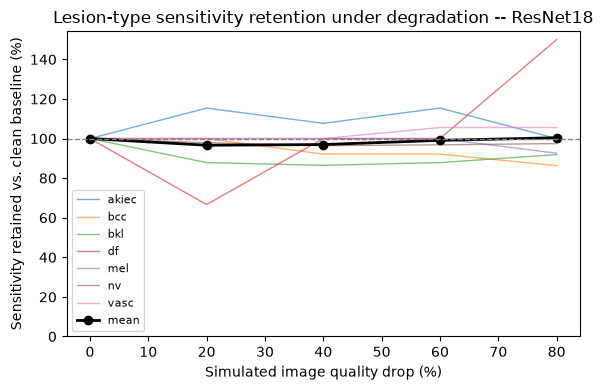

In [11]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(6, 4))
for col in SENS_COLS:
    base = quality_df.loc[quality_df["quality_drop_pct"] == 0, col].iloc[0]
    ax.plot(quality_df["quality_drop_pct"], 100 * quality_df[col] / max(base, 1e-6),
            linewidth=1, alpha=0.6, label=col.removeprefix("sens_"))
ax.plot(quality_df["quality_drop_pct"], quality_df["pct_sensitivity_retained"], marker="o",
        color="black", linewidth=2, label="mean")
ax.axhline(100, linestyle="--", linewidth=1, color="gray")
ax.set_xlabel("Simulated image quality drop (%)")
ax.set_ylabel("Sensitivity retained vs. clean baseline (%)")
ax.set_title("Lesion-type sensitivity retention under degradation -- ResNet18")
ax.set_ylim(bottom=0)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("outputs/sensitivity_retention_curve.png", dpi=150)
plt.show()



## 9. Grad-CAM

For the "why did it flag this" overlay in the clinical-kit UI. Requires backprop through the frozen
backbone's conv layers up to the classifier logit -- frozen weights don't block gradient flow to
activations/inputs, only to the weights themselves, so this works without unfreezing anything.


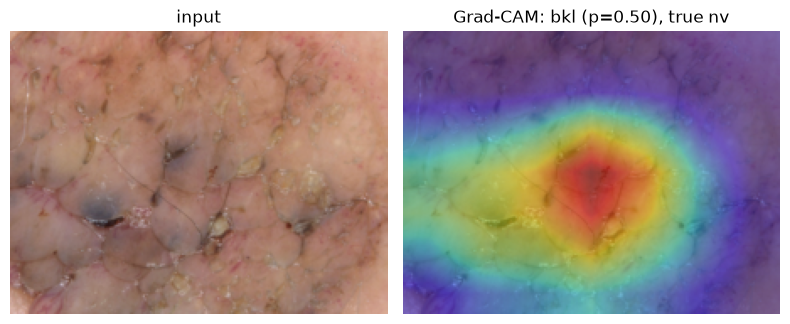

In [12]:

class GradCAM:
    def __init__(self, backbone, head, target_layer_name="layer4"):
        self.backbone = backbone
        self.head = head
        self.activations = None
        self.gradients = None
        layer = dict(backbone.model.named_modules())[target_layer_name]
        layer.register_forward_hook(self._save_activation)
        layer.register_full_backward_hook(self._save_gradient)

    def _save_activation(self, module, inp, out):
        self.activations = out

    def _save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def __call__(self, pil_image):
        x = self.backbone.preprocess(pil_image).unsqueeze(0).to(self.backbone.device)
        x.requires_grad_(True)
        emb = self.backbone.model(x)  # grad-enabled forward; backbone weights stay frozen
        logits, _ = self.head(emb)
        pred = int(logits.argmax(dim=-1))
        self.backbone.model.zero_grad()
        self.head.zero_grad()
        logits[0, pred].backward()

        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=pil_image.size[::-1], mode="bilinear", align_corners=False)
        cam = cam.squeeze().detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam, CLASS_NAMES[pred], torch.softmax(logits, dim=-1)[0, pred].item()


cam_tool = GradCAM(backbone, head)
sample_row = test_df.iloc[0]
sample_img = load_pil(sample_row, CFG.img_dir)
cam, pred_name, prob = cam_tool(sample_img)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample_img); axes[0].set_title("input"); axes[0].axis("off")
axes[1].imshow(sample_img); axes[1].imshow(cam, cmap="jet", alpha=0.45); axes[1].axis("off")
axes[1].set_title(f"Grad-CAM: {pred_name} (p={prob:.2f}), true {sample_row['diagnosis']}")
plt.tight_layout()
plt.savefig("outputs/gradcam_example.png", dpi=150)
plt.show()



## 10. INT8 quantization and ONNX export for the Raspberry Pi artifact

Two INT8 paths: PyTorch dynamic INT8 for local sanity/size check, and final ONNX Runtime INT8 for Pi deployment.


In [13]:
class DeployableModel(nn.Module):
    """Wraps the frozen resnet18 backbone + trained classifier head into one exportable graph --
    this is the artifact that ships to the Pi kit."""

    def __init__(self, backbone, head):
        super().__init__()
        # deep-copy so this wrapper owns independent modules -- quantizing/mutating it must
        # never reach back and change the live backbone/head used elsewhere in the notebook
        self.backbone_model = copy.deepcopy(backbone.model)
        self.classifier = copy.deepcopy(head.classifier)

    def forward(self, x):
        emb = self.backbone_model(x)
        return self.classifier(emb)  # (batch, n_classes)

# Section 9's GradCAM left forward/backward hooks clipped onto backbone.model (layer4), and
# those hooks are still holding a mid-computation (non-leaf) activation/gradient tensor. deepcopy
# can't copy a non-leaf tensor, so clear the hooks on the *source* model before any copying happens.
for m in backbone.model.modules():
    m._forward_hooks.clear()
    m._backward_hooks.clear()
    m._forward_pre_hooks.clear()
    
# make sure deployable is FP32 and on CPU
deployable = DeployableModel(backbone, head).to("cpu").eval()

# save FP32 torch state_dict (for debugging / baseline)
torch.save(deployable.state_dict(), "outputs/melanoma_resnet18_fp32_state_dict.pt")

# create a fresh (independent) DeployableModel and load the saved fp32 weights
quant_src = DeployableModel(backbone, head).to("cpu").eval()
quant_src.load_state_dict(torch.load("outputs/melanoma_resnet18_fp32_state_dict.pt"))

# quantize in-place -- safe now: quant_src is its own copy, not the live head
quantized_model = torch.quantization.quantize_dynamic(
    quant_src, {nn.Linear}, dtype=torch.qint8, inplace=True
)

# save artifacts
torch.save(quantized_model.state_dict(), CFG.torch_int8_path)
torch.save(quantized_model, CFG.torch_int8_path.replace(".pt", "_full.pt"))

# measure sizes (use saved files for accurate size)
print("FP32 state_dict size (MB):", os.path.getsize("outputs/melanoma_resnet18_fp32_state_dict.pt")/1e6)
print("Quantized full model size (MB):", os.path.getsize(CFG.torch_int8_path.replace(".pt", "_full.pt"))/1e6)

FP32 state_dict size (MB): 45.056891
Quantized full model size (MB): 44.870143


In [14]:
import json, torch, onnx
import onnxruntime as ort
from onnxruntime.quantization import quantize_dynamic as ort_quantize_dynamic, QuantType

# 1) Recreate a clean FP32 model from saved state_dict
deployable_fp32 = DeployableModel(backbone, head).to("cpu").eval()
deployable_fp32.load_state_dict(torch.load("outputs/melanoma_resnet18_fp32_state_dict.pt"))

# 2) Clear any forward/backward/pre hooks (GradCAM left hooks cause tracing to fail)
for m in deployable_fp32.backbone_model.modules():
    if hasattr(m, "_forward_hooks"):
        m._forward_hooks.clear()
    if hasattr(m, "_backward_hooks"):
        m._backward_hooks.clear()
    if hasattr(m, "_forward_pre_hooks"):
        m._forward_pre_hooks.clear()

# quick sanity checks
packed_present = any(getattr(m, "_packed_params", None) is not None for m in deployable_fp32.modules())
hooks_present = any((getattr(m, "_forward_hooks", None) and len(m._forward_hooks)) or
                    (getattr(m, "_backward_hooks", None) and len(m._backward_hooks))
                    for m in deployable_fp32.modules())
print("has_packed_params:", packed_present, "has_hooks:", hooks_present)
assert not packed_present, "Model contains packed (quantized) params — load a clean FP32 state_dict."
assert not hooks_present, "Hooks present — cleared above but verify your GradCAM code."

# 3) ONNX export -> ORT dynamic quantize
# Export the eager nn.Module directly (not a torch.jit.trace'd ScriptModule): newer torch versions
# default torch.onnx.export to the dynamo-based exporter, which inspects the model's Python
# `forward` signature to resolve dynamic_axes -- a ScriptModule has no such readable signature,
# which fails with "Failed to convert 'dynamic_axes' to 'dynamic_shapes'". dynamo=False forces the
# older, stable tracing-based exporter, which handles dynamic_axes directly.
dummy_input = torch.randn(1, 3, CFG.img_size, CFG.img_size)

torch.onnx.export(
    deployable_fp32, dummy_input, CFG.onnx_path,
    input_names=["pixel_values"], output_names=["logits"],
    dynamic_axes={"pixel_values": {0: "batch"}, "logits": {0: "batch"}},
    opset_version=18,
    dynamo=False,
)
onnx.checker.check_model(onnx.load(CFG.onnx_path))
print(f"Exported + validated FP32 ONNX model at {CFG.onnx_path}")
with open(CFG.class_names_path, "w") as f:
    json.dump(CLASS_NAMES, f)
print(f"Saved class order {CLASS_NAMES} to {CFG.class_names_path}")

ort_quantize_dynamic(
    model_input=CFG.onnx_path,
    model_output=CFG.onnx_int8_path,
    weight_type=QuantType.QInt8,
)
print(f"Exported INT8 ONNX model to {CFG.onnx_int8_path}")

has_packed_params: False has_hooks: False
Exported + validated FP32 ONNX model at outputs/melanoma_resnet18_fp32.onnx
Saved class order ['akiec', 'bcc', 'bkl', 'df', 'mel', 'nv', 'vasc'] to outputs/class_names.json


Exported INT8 ONNX model to outputs/melanoma_resnet18_int8.onnx



## 11. Re-measure sensitivity retention on the *deployed* artifact

The number that actually matters for the pitch is this one, not the training-time model's. Runs
the same quality-drop sweep as section 8, but through the exported INT8 ONNX model.


In [15]:
def onnx_predict_probs(session, pil_images, tta=False):
    def run(images):
        batch = torch.stack([backbone.preprocess(im) for im in images]).numpy().astype(np.float32)
        logits = session.run(None, {session.get_inputs()[0].name: batch})[0]
        e = np.exp(logits - logits.max(axis=1, keepdims=True))  # softmax
        return e / e.sum(axis=1, keepdims=True)

    probs = run(pil_images)
    if tta:  # same mirror-image averaging as section 8
        probs = (probs + run([im.transpose(Image.Transpose.FLIP_LEFT_RIGHT) for im in pil_images])) / 2
    return probs


def evaluate_onnx_at_quality_drop(session, eval_df, quality_drop_pct, cfg):
    all_labels, all_probs, all_fitz = [], [], []
    n = len(eval_df)
    for start in range(0, n, cfg.batch_size):
        batch_df = eval_df.iloc[start:start + cfg.batch_size]
        imgs = [load_pil(row, cfg.img_dir) for _, row in batch_df.iterrows()]
        if quality_drop_pct > 0:
            imgs = [degrade_image(im, quality_drop_pct, cfg) for im in imgs]
        all_probs.append(onnx_predict_probs(session, imgs, tta=cfg.tta))
        all_labels.extend(batch_df["label"].tolist())
        fitz_col = batch_df["fitzpatrick"] if "fitzpatrick" in batch_df.columns else pd.Series([-1] * len(batch_df))
        all_fitz.extend(fitz_col.tolist())
    return classification_metrics(np.array(all_labels), np.concatenate(all_probs), all_fitz, quality_drop_pct)


if not Path(CFG.onnx_int8_path).exists():
    raise FileNotFoundError(
        f"INT8 ONNX artifact not found at {CFG.onnx_int8_path}. Run the export cell above first."
    )
int8_session = ort.InferenceSession(CFG.onnx_int8_path, providers=["CPUExecutionProvider"])
onnx_results = [
    evaluate_onnx_at_quality_drop(int8_session, test_df, q, CFG) for q in CFG.eval_quality_levels
]
onnx_results_df = pd.DataFrame(onnx_results)
onnx_baseline = onnx_results_df.loc[onnx_results_df["quality_drop_pct"] == 0, "sensitivity"].iloc[0]
onnx_results_df["pct_sensitivity_retained"] = 100 * onnx_results_df["sensitivity"] / max(onnx_baseline, 1e-6)
print(onnx_results_df[["quality_drop_pct", "accuracy", "sensitivity", "auc", "pct_sensitivity_retained"] + SENS_COLS])

print("\nThis table -- INT8 ONNX artifact, sensitivity retained at each quality-drop level -- "

      "is the evidence for the deployment claim. Read a specific number (e.g. the 60% row) "      "off it rather than asserting one.")

   quality_drop_pct  accuracy  sensitivity       auc  \
0                 0  0.695441     0.627820  0.937406   
1                20  0.677983     0.628959  0.932962   
2                40  0.680892     0.631521  0.926183   
3                60  0.666343     0.626748  0.920969   
4                80  0.665373     0.624541  0.917347   

   pct_sensitivity_retained  sens_akiec  sens_bcc  sens_bkl  sens_df  \
0                100.000000     0.37500  0.750000  0.561983   0.3125   
1                100.181481     0.34375  0.750000  0.495868   0.3750   
2                100.589508     0.34375  0.735294  0.545455   0.3750   
3                 99.829310     0.37500  0.691176  0.512397   0.4375   
4                 99.477750     0.34375  0.632353  0.603306   0.5625   

   sens_mel   sens_nv  sens_vasc  
0  0.720339  0.727549   0.947368  
1  0.728814  0.709285   1.000000  
2  0.711864  0.709285   1.000000  
3  0.669492  0.701674   1.000000  
4  0.576271  0.706240   0.947368  

This table -- INT8 


## 12. After this notebook: the Raspberry Pi kit

This notebook's job ends at a trained, quantized, exported model
(`outputs/melanoma_resnet18_int8.onnx`, plus the Grad-CAM and
sensitivity-retention plots for a writeup). The Raspberry Pi clinical kit itself needs, separately:
a camera-capture loop (e.g. `picamera2`) feeding frames to an ONNX Runtime session running on the
Pi, and the Grad-CAM overlay rendered on a small display, entirely offline at inference time,
since the exported artifact has everything it needs baked in. That's a smaller, well-scoped
follow-on project once this notebook's numbers hold up on real data.



## 13. Why this is important

The constraint driving this whole design. A small model (ResNet18, ~11 MB in INT8), quantized,
fully offline inference, and robustness to poor-quality photos. These aren't just an engineering choice, it's what makes the tool usable by the
people who most need it: traveling doctors and community health workers in areas without reliable
connectivity or specialist dermatology access, and individuals who have no practical way to get a
skin lesion looked at at all. A cloud-dependent model is unusable exactly where a melanoma triage
tool would matter most. Keep that framing explicit and central in any writeup. It's the actual
motivation, not a footnote.



## 14. Before this goes anywhere near a conference submission or a patient

- Validate on images that look like the Pi camera's (ordinary clinical photos like PAD-UFES-20),
  not only dermoscopy (BCN20000 / HAM10000).
- Run the Fitzpatrick-stratified sensitivity breakdown (built into `evaluate_at_quality_drop`) on
  real, diverse-skin-tone data before trusting aggregate sensitivity numbers -- this is where
  dermatology AI most often quietly fails, per DDI/Fitzpatrick17k literature.
- Benchmark actual latency/memory on physical Raspberry Pi hardware, not this notebook's host --
  ARM vs. x86 numbers diverge, sometimes significantly.
- Decide what threshold and what "X% sensitivity retained at X% quality drop" claim you're
  actually making, based on the measured curves in sections 8 and 11 -- don't restate a target
  number from the pitch as if it were already demonstrated.
- Once this baseline is validated, try swapping in `torchvision.models.mobilenet_v3_small` as the
  backbone -- same pattern as section 4, likely a stronger fit for the "lightweight, edge-native"
  claim specifically.
- This notebook produces a triage/referral signal, not a diagnosis. Keep that framing explicit in
  any poster, demo, or writeup, especially given the social-impact framing -- a false negative in
  a low-resource setting with no backup dermatologist is a much worse failure mode than in a
  clinic with one.
